In [1]:
%load_ext autoreload
%autoreload 2

from fraudshield.load_data import get_train_test

X_train, X_test, y_train, y_test = get_train_test()

Missing values: 0
Removed 1081 duplicates
Train: (226980, 31) fraud = 0.167%
Test : (56746, 31) fraud = 0.167%


In [2]:
from fraudshield.load_data import make_preprocessor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

baseline = Pipeline([
    ("prep", make_preprocessor()),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000))
])

lr_plain = Pipeline([
    ("prep", make_preprocessor()),
    ("model", LogisticRegression(max_iter=1000))
])

baseline.fit(X_train, y_train)
lr_plain.fit(X_train, y_train)

print("Both models trained")

Both models trained


In [3]:
from fraudshield.evaluation import evaluate_model, compare_results

evaluate_model("LR balanced", baseline, X_test, y_test)
evaluate_model("LR plain", lr_plain, X_test, y_test)

compare_results()

=== LR balanced (threshold = 0.5) ===
              precision    recall  f1-score   support

           0     0.9998    0.9750    0.9872     56651
           1     0.0554    0.8737    0.1041        95

    accuracy                         0.9748     56746
   macro avg     0.5276    0.9243    0.5457     56746
weighted avg     0.9982    0.9748    0.9858     56746

[[55235  1416]
 [   12    83]]
ROC-AUC: 0.9685
PR-AUC : 0.6703
=== LR plain (threshold = 0.5) ===
              precision    recall  f1-score   support

           0     0.9993    0.9998    0.9996     56651
           1     0.8636    0.6000    0.7081        95

    accuracy                         0.9992     56746
   macro avg     0.9315    0.7999    0.8538     56746
weighted avg     0.9991    0.9992    0.9991     56746

[[56642     9]
 [   38    57]]
ROC-AUC: 0.9598
PR-AUC : 0.6927


,PR-AUC,ROC-AUC,Precision,Recall,F1,TP,FP,FN,TN,Threshold
LR plain,0.6927,0.9598,0.8636,0.6000,0.7081,57.0,9.0,38.0,56642.0,0.5
LR balanced,0.6703,0.9685,0.0554,0.8737,0.1041,83.0,1416.0,12.0,55235.0,0.5


In [4]:
for t in [0.5, 0.2, 0.1, 0.05]:
    evaluate_model(f"LR plain @{t}", lr_plain, X_test, y_test, threshold=t, show=False)

compare_results()

,PR-AUC,ROC-AUC,Precision,Recall,F1,TP,FP,FN,TN,Threshold
LR plain,0.6927,0.9598,0.8636,0.6000,0.7081,57.0,9.0,38.0,56642.0,0.50
LR plain @0.5,0.6927,0.9598,0.8636,0.6000,0.7081,57.0,9.0,38.0,56642.0,0.50
LR plain @0.1,0.6927,0.9598,0.8434,0.7368,0.7865,70.0,13.0,25.0,56638.0,0.10
LR plain @0.2,0.6927,0.9598,0.8354,0.6947,0.7586,66.0,13.0,29.0,56638.0,0.20
LR plain @0.05,0.6927,0.9598,0.7629,0.7789,0.7708,74.0,23.0,21.0,56628.0,0.05
LR balanced,0.6703,0.9685,0.0554,0.8737,0.1041,83.0,1416.0,12.0,55235.0,0.50


LR plain precision at recall >= 0.874: 0.010539367637941723


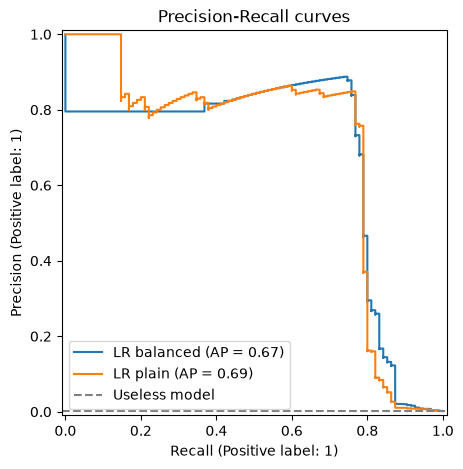

In [5]:
from sklearn.metrics import precision_recall_curve
from fraudshield.evaluation import plot_pr_curves

# What precision does LR plain get when it reaches the recall of LR balanced (0.874)?
y_proba_plain = lr_plain.predict_proba(X_test)[:, 1]
prec, rec, thr = precision_recall_curve(y_test, y_proba_plain)
print("LR plain precision at recall >= 0.874:", prec[rec >= 0.8737].max())

plot_pr_curves({"LR balanced": baseline, "LR plain": lr_plain},
               X_test, y_test, save_path="../reports/figures/pr_curves.png")

In [6]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=4,
    eval_metric="aucpr",
    n_jobs=-1,
    random_state=42,
)
xgb.fit(X_train, y_train)

evaluate_model("XGB plain", xgb, X_test, y_test)
compare_results()


=== XGB plain (threshold = 0.5) ===
              precision    recall  f1-score   support

           0     0.9995    0.9999    0.9997     56651
           1     0.9571    0.7053    0.8121        95

    accuracy                         0.9995     56746
   macro avg     0.9783    0.8526    0.9059     56746
weighted avg     0.9994    0.9995    0.9994     56746

[[56648     3]
 [   28    67]]
ROC-AUC: 0.9729
PR-AUC : 0.8053


,PR-AUC,ROC-AUC,Precision,Recall,F1,TP,FP,FN,TN,Threshold
XGB plain,0.8053,0.9729,0.9571,0.7053,0.8121,67.0,3.0,28.0,56648.0,0.50
LR plain @0.5,0.6927,0.9598,0.8636,0.6000,0.7081,57.0,9.0,38.0,56642.0,0.50
LR plain,0.6927,0.9598,0.8636,0.6000,0.7081,57.0,9.0,38.0,56642.0,0.50
LR plain @0.1,0.6927,0.9598,0.8434,0.7368,0.7865,70.0,13.0,25.0,56638.0,0.10
LR plain @0.2,0.6927,0.9598,0.8354,0.6947,0.7586,66.0,13.0,29.0,56638.0,0.20
LR plain @0.05,0.6927,0.9598,0.7629,0.7789,0.7708,74.0,23.0,21.0,56628.0,0.05
LR balanced,0.6703,0.9685,0.0554,0.8737,0.1041,83.0,1416.0,12.0,55235.0,0.50


In [7]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {"LR balanced": baseline, "LR plain": lr_plain, "XGB plain": xgb}

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="average_precision")
    print(f"{name}: PR-AUC = {scores.mean():.3f} ± {scores.std():.3f}")

LR balanced: PR-AUC = 0.754 ± 0.027
LR plain: PR-AUC = 0.757 ± 0.030
XGB plain: PR-AUC = 0.842 ± 0.027


In [8]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=42,
)
rf.fit(X_train, y_train)

evaluate_model("RF plain", rf, X_test, y_test, show=False)

scores = cross_val_score(rf, X_train, y_train, cv=cv, scoring="average_precision")
print(f"RF plain: PR-AUC = {scores.mean():.3f} ± {scores.std():.3f}")

compare_results()

RF plain: PR-AUC = 0.835 ± 0.031


,PR-AUC,ROC-AUC,Precision,Recall,F1,TP,FP,FN,TN,Threshold
XGB plain,0.8053,0.9729,0.9571,0.7053,0.8121,67.0,3.0,28.0,56648.0,0.50
RF plain,0.7937,0.9369,0.9726,0.7474,0.8452,71.0,2.0,24.0,56649.0,0.50
LR plain,0.6927,0.9598,0.8636,0.6000,0.7081,57.0,9.0,38.0,56642.0,0.50
LR plain @0.5,0.6927,0.9598,0.8636,0.6000,0.7081,57.0,9.0,38.0,56642.0,0.50
LR plain @0.05,0.6927,0.9598,0.7629,0.7789,0.7708,74.0,23.0,21.0,56628.0,0.05
LR plain @0.2,0.6927,0.9598,0.8354,0.6947,0.7586,66.0,13.0,29.0,56638.0,0.20
LR plain @0.1,0.6927,0.9598,0.8434,0.7368,0.7865,70.0,13.0,25.0,56638.0,0.10
LR balanced,0.6703,0.9685,0.0554,0.8737,0.1041,83.0,1416.0,12.0,55235.0,0.50


In [9]:
from catboost import CatBoostClassifier

cat = CatBoostClassifier(
    iterations=300,
    learning_rate=0.1,
    depth=6,
    eval_metric="PRAUC",
    random_seed=42,
    thread_count=-1,
    verbose=0,
)
cat.fit(X_train, y_train)

evaluate_model("CatBoost plain", cat, X_test, y_test, show=False)

scores = cross_val_score(cat, X_train, y_train, cv=cv, scoring="average_precision")
print(f"CatBoost plain: PR-AUC = {scores.mean():.3f} ± {scores.std():.3f}")

compare_results()

CatBoost plain: PR-AUC = 0.850 ± 0.030


,PR-AUC,ROC-AUC,Precision,Recall,F1,TP,FP,FN,TN,Threshold
CatBoost plain,0.8265,0.9825,0.9714,0.7158,0.8242,68.0,2.0,27.0,56649.0,0.50
XGB plain,0.8053,0.9729,0.9571,0.7053,0.8121,67.0,3.0,28.0,56648.0,0.50
RF plain,0.7937,0.9369,0.9726,0.7474,0.8452,71.0,2.0,24.0,56649.0,0.50
LR plain @0.1,0.6927,0.9598,0.8434,0.7368,0.7865,70.0,13.0,25.0,56638.0,0.10
LR plain,0.6927,0.9598,0.8636,0.6000,0.7081,57.0,9.0,38.0,56642.0,0.50
LR plain @0.5,0.6927,0.9598,0.8636,0.6000,0.7081,57.0,9.0,38.0,56642.0,0.50
LR plain @0.2,0.6927,0.9598,0.8354,0.6947,0.7586,66.0,13.0,29.0,56638.0,0.20
LR plain @0.05,0.6927,0.9598,0.7629,0.7789,0.7708,74.0,23.0,21.0,56628.0,0.05
LR balanced,0.6703,0.9685,0.0554,0.8737,0.1041,83.0,1416.0,12.0,55235.0,0.50
